# Forward kinematics complète du robot

Pour déterminer la FK, on procède de la façon suivante dans ce notebook :

**angles des 6 actionneurs → positions des 3 effecteurs des mécanismes 5-barres → positions du triangle →  affichage des solutions.**
Plus généralement on a :

### Partie 1 : FK des 3 mécanismes 5-bars en fonction de q1,q2,q3,q4,q5,q6
    - FK de chaque mécanisme 5 bars dans son repère local (origine au moteur A)
    - Transformation des coordonnées des 3 effecteurs dans le repère global
    
### Partie 2 : FK de l'effecteur (triangle) en fonction des positions des trois effecteurs des 5 bars


# 1 — Forward Kinematic d'un mécanisme 5 barres

## 1.1 Solution numérique

In [1]:
import numpy as np
from scipy.optimize import fsolve

# Longueurs
l1 = 1
l2 = 1
l3 = 1
l4 = 1
l5 = 1

# Angles moteurs
#theta1 = 3 * np.pi / 5   # 108 deg
#theta2 = 2 * np.pi / 5   # 72 deg
theta1 =  90/180*np.pi 
theta2 =   200/180*np.pi

def xc(theta1):
    return l1 * np.cos(theta1)


def yc(theta1):
    return l1 * np.sin(theta1)


def xd(theta2):
    return l5 + l4 * np.cos(theta2)


def yd(theta2):
    return l4 * np.sin(theta2)




def equations(theta):
    theta3 = theta[0]
    theta4 = theta[1]

    f1 = (
        xc(theta1)
        + l2 * np.cos(theta1 + theta3)
        - (
            xd(theta2)
            + l3 * np.cos(theta2 + np.pi - theta4)
        )
    )

    f2 = (
        yc(theta1)
        + l2 * np.sin(theta1 + theta3)
        - (
            yd(theta2)
            + l3 * np.sin(theta2 + np.pi - theta4)
        )
    )

    return [f1, f2]


# Valeurs initiales
theta0 = [0, 0]

# Résolution
theta_sol = fsolve(equations, theta0)

theta3 = theta_sol[0]
theta4 = theta_sol[1]

# Position de l'effecteur :
xe = l1 * np.cos(theta1) + l2 * np.cos(theta1 + theta3)
ye = l1 * np.sin(theta1) + l2 * np.sin(theta1 + theta3)

theta3 = np.degrees(theta_sol[0])
theta4 = np.degrees(theta_sol[1])

print("theta3 =", theta3, "deg")
print("theta4 =", theta4, "deg")
print("xe = ",xe," ye = ",ye)

theta3 = 134.77043441226283 deg
theta4 = -120.3755914724334 deg
xe =  -0.7099342451768279  ye =  0.2957320342900669


### Affichage de la solution NUMERIQUE

theta3 = 134.77043441226283 deg
theta4 = -120.3755914724334 deg
E depuis gauche = [-0.70993425  0.29573203]
E depuis droite = [-0.70993425  0.29573203]
Erreur fermeture = 1.3572562789364665e-11


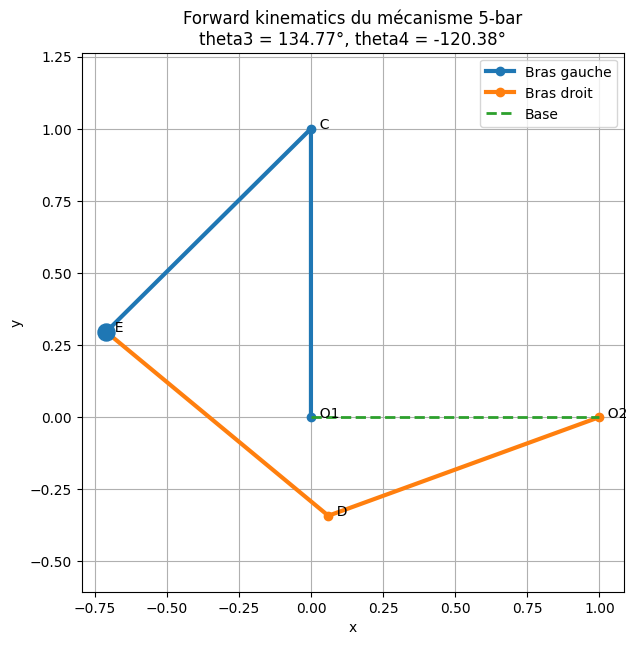

In [2]:
import numpy as np
import matplotlib.pyplot as plt

# ---------------------------------------------------------
# Angles issus de fsolve : garder les radians pour les calculs
# ---------------------------------------------------------

theta3_rad = theta_sol[0]
theta4_rad = theta_sol[1]

# Versions en degrés uniquement pour l'affichage
theta3_deg = np.degrees(theta3_rad)
theta4_deg = np.degrees(theta4_rad)

# ---------------------------------------------------------
# Positions des points
# ---------------------------------------------------------

# Pivots fixes
O1 = np.array([0.0, 0.0])
O2 = np.array([l5, 0.0])

# Coude gauche C
C = np.array([
    l1 * np.cos(theta1),
    l1 * np.sin(theta1)
])

# Coude droit D
D = np.array([
    l5 + l4 * np.cos(theta2),
    l4 * np.sin(theta2)
])

# Effecteur calculé depuis le bras gauche
E_left = np.array([
    C[0] + l2 * np.cos(theta1 + theta3_rad),
    C[1] + l2 * np.sin(theta1 + theta3_rad)
])

# Effecteur calculé depuis le bras droit
E_right = np.array([
    D[0] + l3 * np.cos(theta2 + np.pi - theta4_rad),
    D[1] + l3 * np.sin(theta2 + np.pi - theta4_rad)
])

# On prend la moyenne des deux
# Elles devraient être quasiment identiques si fsolve a bien convergé
E = 0.5 * (E_left + E_right)

# ---------------------------------------------------------
# Vérification numérique
# ---------------------------------------------------------

print("theta3 =", theta3_deg, "deg")
print("theta4 =", theta4_deg, "deg")

print("E depuis gauche =", E_left)
print("E depuis droite =", E_right)
print("Erreur fermeture =", np.linalg.norm(E_left - E_right))

# ---------------------------------------------------------
# Affichage
# ---------------------------------------------------------

plt.figure(figsize=(7, 7))

# Bras gauche O1 -> C -> E
plt.plot(
    [O1[0], C[0], E[0]],
    [O1[1], C[1], E[1]],
    '-o',
    linewidth=3,
    label="Bras gauche"
)

# Bras droit O2 -> D -> E
plt.plot(
    [O2[0], D[0], E[0]],
    [O2[1], D[1], E[1]],
    '-o',
    linewidth=3,
    label="Bras droit"
)

# Base
plt.plot(
    [O1[0], O2[0]],
    [O1[1], O2[1]],
    '--',
    linewidth=2,
    label="Base"
)

# ---------------------------------------------------------
# Noms des points
# ---------------------------------------------------------

plt.text(O1[0], O1[1], "  O1")
plt.text(O2[0], O2[1], "  O2")
plt.text(C[0], C[1], "  C")
plt.text(D[0], D[1], "  D")
plt.text(E[0], E[1], "  E")

# Mettre en évidence l'effecteur
plt.scatter(E[0], E[1], s=150, zorder=5)

# ---------------------------------------------------------
# Mise en forme
# ---------------------------------------------------------

plt.axis("equal")
plt.grid()

plt.xlabel("x")
plt.ylabel("y")

plt.title(
    f"Forward kinematics du mécanisme 5-bar\n"
    f"theta3 = {theta3_deg:.2f}°, theta4 = {theta4_deg:.2f}°"
)

plt.legend()
plt.show()

## 1.2 Solution analytique

In [3]:
import numpy as np

# Constantes
l1 = 0.2
l2 = 0.2
l3 = 0.2
l4 = 0.2
l5 = 0.2

def x_c(theta1):
    return l1 * np.cos(theta1)

def y_c(theta1):
    return l1 * np.sin(theta1)

def x_d(theta2):
    return l5 + l4 * np.cos(theta2)

def y_d(theta2):
    return l4 * np.sin(theta2)


def solve_position(theta1, theta2):

    xd = x_d(theta2)
    yd = y_d(theta2)
    xc = x_c(theta1)
    yc = y_c(theta1)

    C = (xc, yc)
    D = (xd, yd)

    dx = xd - xc
    dy = yd - yc
    d = np.hypot(dx, dy)

    if np.isclose(d, 0):
        if np.isclose(l2, l3):
            return "Infinite solutions"
        return []

    if d > l2 + l3 or d < abs(l2 - l3):
        return []

    a = (l2**2 - l3**2 + d**2) / (2*d)
    h = np.sqrt(max(0, l2**2 - a**2))

    xh = xc + a * dx / d
    yh = yc + a * dy / d

    # Deux solutions
    E1 = (xh - h * dy / d, yh + h * dx / d)
    E2 = (xh + h * dy / d, yh - h * dx / d)

    # Produit vectoriel CE x DE
    cross = (
        (E1[0] - xc) * (E1[1] - yd)
        - (E1[1] - yc) * (E1[0] - xd)
    )

    if cross < 0:
        E1, E2 = E2, E1

    return E1, E2, C, D


### Affichage de la solution ANALYTIQUE (+ choix de la bonne solution)

pour choisir la bonne solution on calcul le produit vectoriel CD x CE :
- si le signe de la composante s est positive alors on a la bonne solution

In [4]:
def side_CD(C, D, E):
    return (
        (D[0] - C[0]) * (E[1] - C[1])
        - (D[1] - C[1]) * (E[0] - C[0])
    )
def plot_solutions(theta1, theta2):

    solutions = [0,0]
    solutions[0] = solve_position(theta1, theta2)[0]
    solutions[1] = solve_position(theta1, theta2)[1]

    if solutions == []:
        print("Aucune solution")
        return

    if solutions == "Infinite solutions":
        print("Infinité de solutions")
        return

    # Points fixes
    O1 = np.array([0.0, 0.0])
    O2 = np.array([l5, 0.0])

    # Coudes
    C = np.array([
        xc(theta1),
        yc(theta1)
    ])

    D = np.array([
        xd(theta2),
        yd(theta2)
    ])

    # -----------------------------------------------------
    # Déterminer quelle solution est la bonne
    # -----------------------------------------------------

    E1 = np.array(solutions[0])
    E2 = np.array(solutions[1])

    s1 = side_CD(C, D, E1)
    s2 = side_CD(C, D, E2)

    # Dans ta convention, on choisit le côté s > 0
    if s1 > 0:
        selected_index = 0
    elif s2 > 0:
        selected_index = 1
    else:
        selected_index = None

    # -----------------------------------------------------
    # Afficher une figure par solution
    # -----------------------------------------------------

    for i, E in enumerate(solutions):

        E = np.array(E)

        plt.figure(figsize=(7, 7))

        # Bras gauche
        plt.plot(
            [O1[0], C[0], E[0]],
            [O1[1], C[1], E[1]],
            '-o',
            linewidth=3,
            label="Bras gauche"
        )

        # Bras droit
        plt.plot(
            [O2[0], D[0], E[0]],
            [O2[1], D[1], E[1]],
            '-o',
            linewidth=3,
            label="Bras droit"
        )

        # Base
        plt.plot(
            [O1[0], O2[0]],
            [O1[1], O2[1]],
            '--',
            linewidth=2,
            label="Base"
        )

        # Ligne C-D pour visualiser le critère
        plt.plot(
            [C[0], D[0]],
            [C[1], D[1]],
            ':',
            linewidth=2,
            label="Droite CD"
        )

        # -------------------------------------------------
        # Labels
        # -------------------------------------------------

        plt.text(O1[0], O1[1], " O1")
        plt.text(O2[0], O2[1], " O2")
        plt.text(C[0], C[1], " C")
        plt.text(D[0], D[1], " D")
        plt.text(E[0], E[1], " E")

        # Effecteur
        plt.scatter(
            E[0],
            E[1],
            s=150,
            zorder=5
        )

        # -------------------------------------------------
        # Affichage des coordonnées
        # -------------------------------------------------

        side_value = side_CD(C, D, E)

        print(f"\nSolution {i+1}")
        print(f"C = ({C[0]:.4f}, {C[1]:.4f})")
        print(f"D = ({D[0]:.4f}, {D[1]:.4f})")
        print(f"E = ({E[0]:.4f}, {E[1]:.4f})")
        print(f"side_CD = {side_value:.6f}")

        if i == selected_index:
            print(">>> SOLUTION À CHOISIR <<<")

        # -------------------------------------------------
        # Mise en forme
        # -------------------------------------------------

        plt.axis("equal")
        plt.grid()

        plt.xlabel("x")
        plt.ylabel("y")

        if i == selected_index:
            plt.title(
                f"Forward kinematics - Solution {i+1} - À CHOISIR"
            )
        else:
            plt.title(
                f"Forward kinematics - Solution {i+1}"
            )

        plt.legend()
        plt.show()

    # -----------------------------------------------------
    # Résumé final
    # -----------------------------------------------------

    if selected_index is not None:
        E_selected = np.array(solutions[selected_index])

        print("\n----------------------------")
        print(f"Solution retenue : {selected_index + 1}")
        print(
            f"E = ({E_selected[0]:.4f}, "
            f"{E_selected[1]:.4f})"
        )
        print("----------------------------")

        return E_selected

    else:
        print("Impossible de sélectionner une solution.")
        return None


Solution 1
C = (0.0000, 0.2000)
D = (0.0121, -0.0684)
E = (0.1540, 0.0724)
side_CD = 0.039809
>>> SOLUTION À CHOISIR <<<


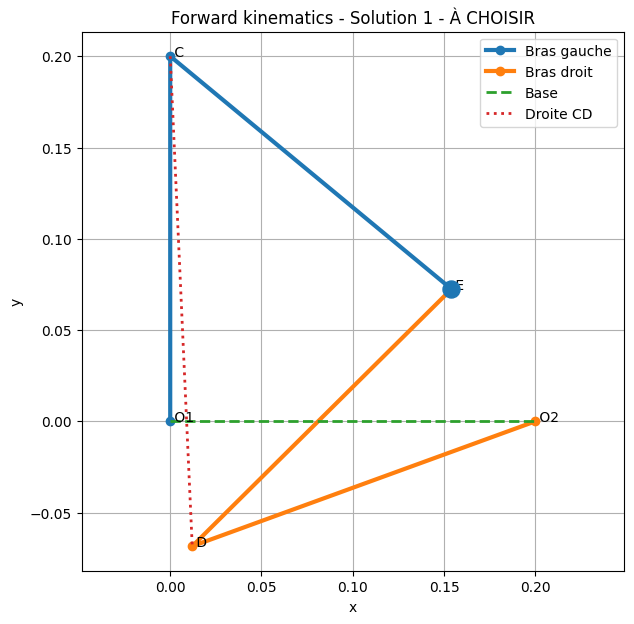


Solution 2
C = (0.0000, 0.2000)
D = (0.0121, -0.0684)
E = (-0.1420, 0.0591)
side_CD = -0.039809


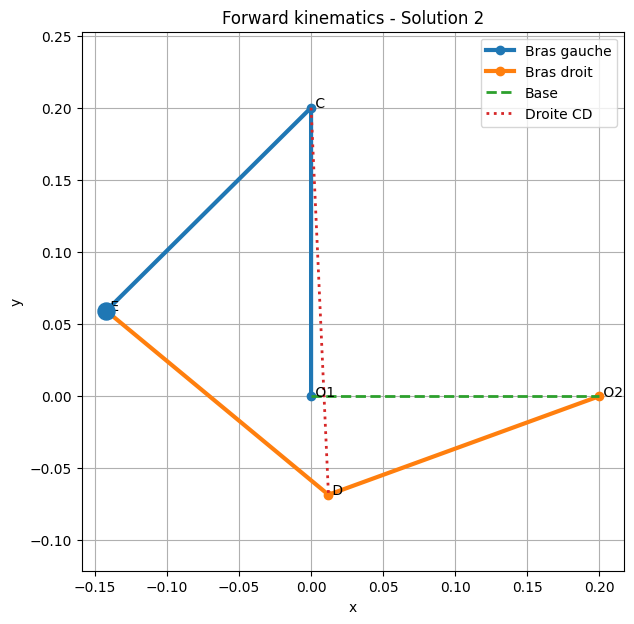


----------------------------
Solution retenue : 1
E = (0.1540, 0.0724)
----------------------------


array([0.15404832, 0.07244956])

In [5]:
theta1 =  90/180*np.pi 
theta2 =   200/180*np.pi
plot_solutions(theta1, theta2)

# 2 — Utilisation de solve_position pour déterminer la position des 3 effecteurs dans le repère x y
– Calcule la position de chacun des 3 effecteurs dans son repère local (2 solutions)  
– Sélectionne la bonne solution avec le produit vectoriel  
– Transforme les positions en les exprimant dans le repère global x y

<img src="schema_forward_2.jpeg" width="500">

In [6]:
import numpy as np

# Positions fixes des 6 actionneurs
def compute_fixed_points():

    # Longueurs
    AB = BC = CD = DE = EA = CF = FF = 0.2
    linkLengths = [AB, BC, CD, DE, EA, CF, FF]

    # Position et orientation du repère du 5-bar 2
    A1A2x = (0.5 + np.cos(np.pi/3) + 2*np.cos(np.pi/6)
             + np.cos(5*np.pi/6 - 2*np.pi/5)) * 0.2

    A1A2y = (np.sin(2*np.pi/5) + np.sin(4*np.pi/5) + 1
             + np.sin(np.pi/3) + np.sin(2*np.pi/3)
             + np.sin(2*np.pi/3 + 2*np.pi/5)) * 0.2

    A1A2t = 2*np.pi/3

    # Position et orientation du repère du 5-bar 3
    A1A3x = -(0.5 + np.cos(np.pi/3) + np.cos(np.pi/6)
              + np.cos(4*np.pi/5 - np.pi/3
                       + np.cos(2*np.pi/5 - np.pi/3))) * 0.2

    A1A3y = A1A2y + np.sin(2*np.pi/3) * 0.2

    A1A3t = -2*np.pi/3

    # Points fixes du mécanisme 2
    P3 = np.array([A1A2x, A1A2y])

    P4 = P3 + EA * np.array([
        np.cos(A1A2t),
        np.sin(A1A2t)
    ])

    # Points fixes du mécanisme 3
    P5 = np.array([A1A3x, A1A3y])

    P6 = P5 + EA * np.array([
        np.cos(A1A3t),
        np.sin(A1A3t)
    ])

    return P3, P4, P5, P6

P1 = np.array([0.0, 0.0])
P2 = np.array([0.2, 0.0])

P3, P4, P5, P6 = compute_fixed_points()

# ============================================================
# Passage repère local du 5-bar -> repère global
# ============================================================

def local_to_global(p_local, P_left, P_right):
    """
    p_local :
        position retournée par solve_position(),
        exprimée dans le repère du 5-bar.

    P_left :
        position globale de l'actionneur gauche.

    P_right :
        position globale de l'actionneur droit.

    Le repère local est défini par :
        origine = P_left
        axe x   = direction P_left -> P_right
    """

    # Direction du x local exprimée dans le repère global
    dx = P_right[0] - P_left[0]
    dy = P_right[1] - P_left[1]

    phi = np.arctan2(dy, dx)

    # Matrice de rotation local -> global
    R = np.array([
        [np.cos(phi), -np.sin(phi)],
        [np.sin(phi),  np.cos(phi)]
    ])

    # Rotation + translation
    return P_left + R @ np.asarray(p_local)


# ============================================================
# Calcul des trois effecteurs
# ============================================================

def compute_effectors(theta_1, theta_2,
                      theta_3, theta_4,
                      theta_5, theta_6):

    # 5-bar 1 : origine au point 1
    F_local, _, C1_local, D1_local = solve_position(theta_1, theta_2)

    F = local_to_global(F_local, P1, P2)
    C1 = local_to_global(C1_local, P1, P2)
    D1 = local_to_global(D1_local, P1, P2)

    # 5-bar 2 : origine au point 3
    E34_local, _, C2_local, D2_local = solve_position(theta_3, theta_4)

    E34 = local_to_global(E34_local, P3, P4)
    C2 = local_to_global(C2_local, P3, P4)
    D2 = local_to_global(D2_local, P3, P4)

    # 5-bar 3 : origine au point 5
    E56_local, _, C3_local, D3_local = solve_position(theta_5, theta_6)

    E56 = local_to_global(E56_local, P5, P6)
    C3 = local_to_global(C3_local, P5, P6)
    D3 = local_to_global(D3_local, P5, P6)

    return (F, E34, E56), (C1, D1, C2, D2, C3, D3)

### Vérification intermédiaire : affichage des 3 mécanismes 5-barres

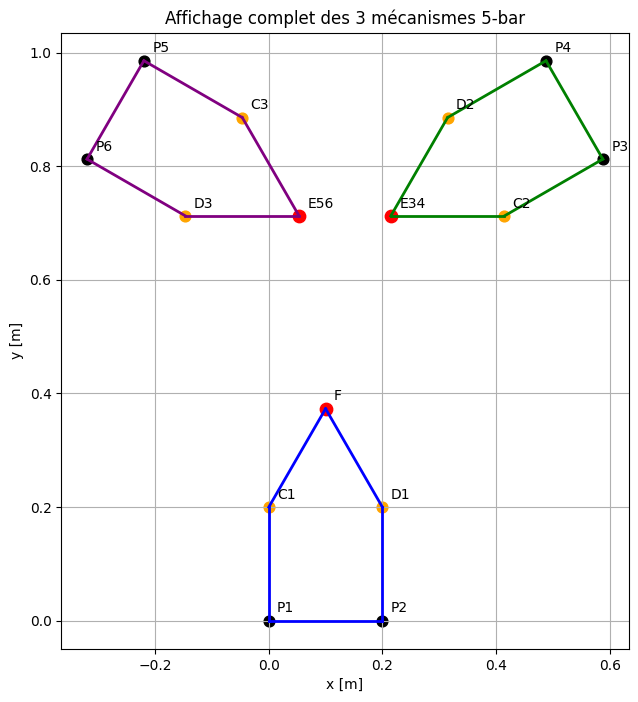

In [7]:
import matplotlib.pyplot as plt
import numpy as np

# Angles des 6 actionneurs (radians)
theta = [np.pi/2, np.pi/2, np.pi/2,
         np.pi/2, np.pi/2, np.pi/2]

# Calcul des positions
(F, E34, E56), (C1, D1, C2, D2, C3, D3) = compute_effectors(*theta)

# Affichage
fig, ax = plt.subplots(figsize=(8, 8))

# Tous les points
points = {
    "P1": P1, "P2": P2, "P3": P3, "P4": P4, "P5": P5, "P6": P6,
    "C1": C1, "D1": D1, "C2": C2, "D2": D2, "C3": C3, "D3": D3,
    "F": F, "E34": E34, "E56": E56
}

# Affichage des points
for name, p in points.items():
    if name in ["F", "E34", "E56"]:
        ax.scatter(*p, color="red", s=80)
    elif name.startswith("C") or name.startswith("D"):
        ax.scatter(*p, color="orange", s=60)
    else:
        ax.scatter(*p, color="black", s=60)

    ax.annotate(name, p, xytext=(6, 6), textcoords="offset points")

# Barres des 3 mécanismes
mechanisms = [
    # mécanisme 1
    {
        "bars": [(P1, C1), (C1, F), (F, D1), (D1, P2), (P1, P2)],
        "color": "blue"
    },
    # mécanisme 2
    {
        "bars": [(P3, C2), (C2, E34), (E34, D2), (D2, P4), (P3, P4)],
        "color": "green"
    },
    # mécanisme 3
    {
        "bars": [(P5, C3), (C3, E56), (E56, D3), (D3, P6), (P5, P6)],
        "color": "purple"
    }
]

for mech in mechanisms:
    color = mech["color"]
    for A, B in mech["bars"]:
        ax.plot([A[0], B[0]], [A[1], B[1]], color=color, linewidth=2)

ax.set_aspect("equal")
ax.set_xlabel("x [m]")
ax.set_ylabel("y [m]")
ax.set_title("Affichage complet des 3 mécanismes 5-bar")
ax.grid(True)

plt.show()

# 3 — Fonction calculant la position de l'effecteur global (triangle ABC)
## Entrées : 
- x1,2,3 et y1,2,3 positions des effecteurs des 3 mécanismes 5 barres
- l longueur des barres reliant les mécanismes 5 barres à l'effecteur triangulaire
- d longueur des côtés du triangle

## Sorties :
- A, B, C position des 3 sommets de l'effecteur

## Principe du programme :
on paramètre le triangle équilatéral ABC avec X,Y,theta (X et Y position du point A, et theta angle entre la droite AB et l'axe horizontale mesuré au point A)  
on soustrait les équations et on résout un système linéaire pour obtenir X(theta) et Y(theta)  
on réinjecte X(theta) et Y(theta) dans la première équation  
on résout numériquement F(theta)=0  
on reconstruit A,B,C

<img src="schema_forward_1.jpg" width="500">

In [8]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import root_scalar


def solve_triangle_fk(x1, y1, x2, y2, x3, y3, l, d,
                      theta_min= -np.pi,
                      theta_max= np.pi,
                      n_samples=2000):
 
    # ------------------------------------------------------------
    # 1) Parametrisation de A,B,C et résolution du système linéaire pour trouver X(theta) et Y(theta)
    # ------------------------------------------------------------

    def XY_from_theta(theta):

        ux = d * np.cos(theta)
        uy = d * np.sin(theta)

        vx = d * np.cos(theta + np.pi / 3)
        vy = d * np.sin(theta + np.pi / 3)

        # Coefficients du système linéaire :
        # a1 X + b1 Y = c1
        # a2 X + b2 Y = c2

        a1 = 2 * (x1 - x2 + ux)
        b1 = 2 * (y1 - y2 + uy)

        c1 = (
            x1**2 + y1**2
            - (ux - x2)**2
            - (uy - y2)**2
        )

        a2 = 2 * (x1 - x3 + vx)
        b2 = 2 * (y1 - y3 + vy)

        c2 = (
            x1**2 + y1**2
            - (vx - x3)**2
            - (vy - y3)**2
        )

        # Déterminant
        Delta = a1 * b2 - a2 * b1

        if abs(Delta) < 1e-10:
            return None

        # Règle de Cramer pour résoudre le système linéaire
        X = (c1 * b2 - c2 * b1) / Delta
        Y = (a1 * c2 - a2 * c1) / Delta

        return X, Y

    # ------------------------------------------------------------
    # 2) Substitution de X(theta) et Y(theta) dans la première équation
    # -----------------------------------------------------------

    def F(theta):

        result = XY_from_theta(theta)

        if result is None:
            return np.nan

        X, Y = result

        return (X - x1)**2 + (Y - y1)**2 - l**2

    # ------------------------------------------------------------
    # 3) Recherche de toutes les racines en theta
    # ------------------------------------------------------------

    theta_values = np.linspace(theta_min, theta_max, n_samples)

    solutions = []

    for i in range(len(theta_values) - 1):

        th1 = theta_values[i]
        th2 = theta_values[i + 1]

        f1 = F(th1)
        f2 = F(th2)

        if np.isnan(f1) or np.isnan(f2):
            continue

        # On cherche un changement de signe
        if f1 * f2 < 0:

            try:
                sol = root_scalar(
                    F,
                    bracket=[th1, th2],
                    method='brentq'
                )

                theta = sol.root

                X, Y = XY_from_theta(theta)

                # ------------------------------------------------
                # 4) Reconstruction de A, B, C
                # ------------------------------------------------

                xa = X
                ya = Y

                xb = X + d * np.cos(theta)
                yb = Y + d * np.sin(theta)

                xc = X + d * np.cos(theta + np.pi / 3)
                yc = Y + d * np.sin(theta + np.pi / 3)

                # Eviter les doublons
                duplicate = False

                for s in solutions:
                    if abs(theta - s["theta"]) < 1e-6:
                        duplicate = True
                        break

                if not duplicate:
                    solutions.append({
                        "theta": theta,
                        "A": (xa, ya),
                        "B": (xb, yb),
                        "C": (xc, yc)
                    })

            except ValueError:
                pass

    return solutions

### Fonction d'affichage des solutions du triangle seul

In [9]:
def plot_solution(sol, x1, y1, x2, y2, x3, y3):

    P1 = np.array([x1, y1])
    P2 = np.array([x2, y2])
    P3 = np.array([x3, y3])

    A = np.array(sol["A"])
    B = np.array(sol["B"])
    C = np.array(sol["C"])

    plt.figure(figsize=(7, 7))

    # Barres extérieures
    plt.plot([P1[0], A[0]], [P1[1], A[1]], '-o')
    plt.plot([P2[0], B[0]], [P2[1], B[1]], '-o')
    plt.plot([P3[0], C[0]], [P3[1], C[1]], '-o')

    # Triangle ABC
    plt.plot([A[0], B[0]], [A[1], B[1]], '-o')
    plt.plot([B[0], C[0]], [B[1], C[1]], '-o')
    plt.plot([C[0], A[0]], [C[1], A[1]], '-o')

    # Points
    plt.scatter(
        [P1[0], P2[0], P3[0]],
        [P1[1], P2[1], P3[1]],
        s=100
    )

    plt.scatter(
        [A[0], B[0], C[0]],
        [A[1], B[1], C[1]],
        s=100
    )

    # Noms des points
    plt.text(P1[0], P1[1], " P1")
    plt.text(P2[0], P2[1], " P2")
    plt.text(P3[0], P3[1], " P3")

    plt.text(A[0], A[1], " A")
    plt.text(B[0], B[1], " B")
    plt.text(C[0], C[1], " C")

    # ---------------------------------------
    # Direction theta = 0
    # ---------------------------------------

    plt.axhline(
        y=A[1],
        linestyle="--",
        label=r"$\theta = 0$"
    )

    plt.axis("equal")
    plt.grid()

    plt.xlabel("x")
    plt.ylabel("y")

    plt.title(
        f"theta = {np.degrees(sol['theta']):.2f}°"
    )

    plt.legend()
    plt.show()

### Vérification intermédiaire du solveur du triangle avec des paramètres simples

In [10]:
x1, y1 = 0.1, 0.373205
x2, y2 = 0.214787, 0.712596
x3, y3 = 0.053307, 0.712596

l = 0.2
d = 0.2


sol = solve_triangle_fk(
    x1, y1,
    x2, y2,
    x3, y3,
    l, d
)

### Affichage des solutions de cette vérification


Solution 1
A = (-0.0852, 0.4487)
B = (0.0583, 0.5880)
C = (-0.1341, 0.6427)
theta = 44.14°


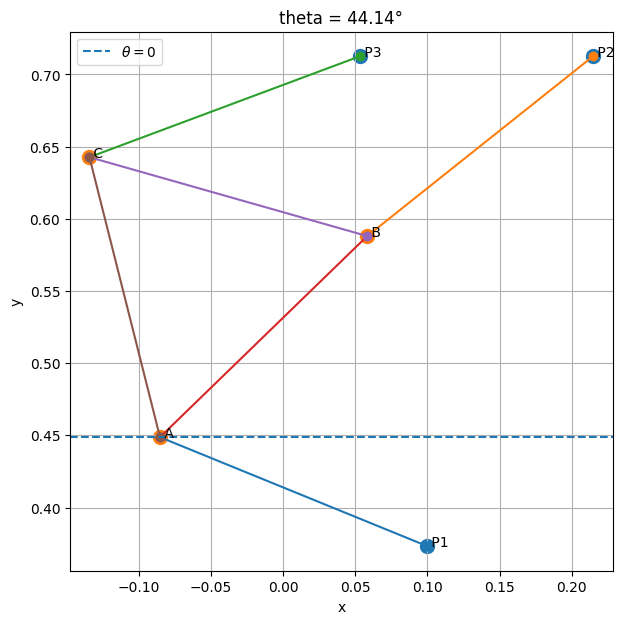


Solution 2
A = (0.2986, 0.3969)
B = (0.3683, 0.5843)
C = (0.1711, 0.5509)
theta = 69.62°


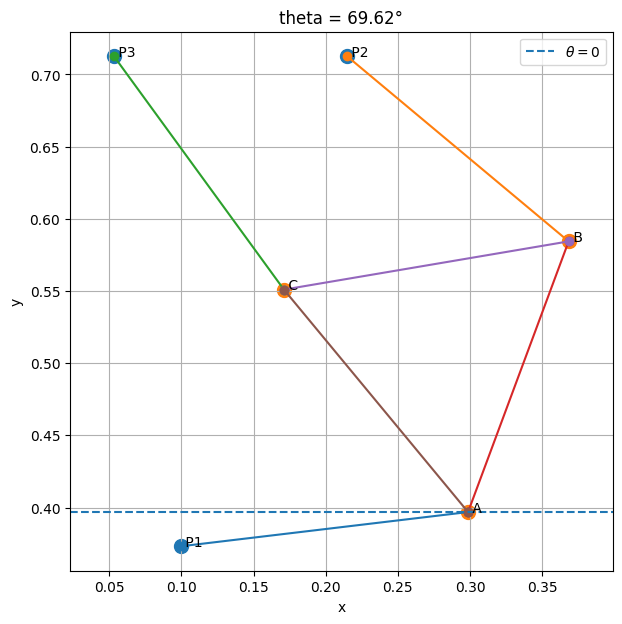


Solution 3
A = (0.0553, 0.5682)
B = (0.0219, 0.7653)
C = (-0.1322, 0.6378)
theta = 99.63°


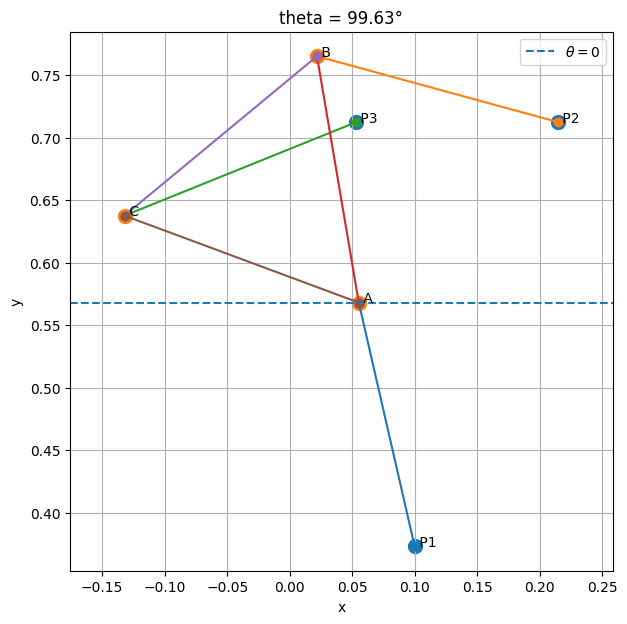


Solution 4
A = (0.1298, 0.5710)
B = (0.0161, 0.7355)
C = (-0.0695, 0.5548)
theta = 124.65°


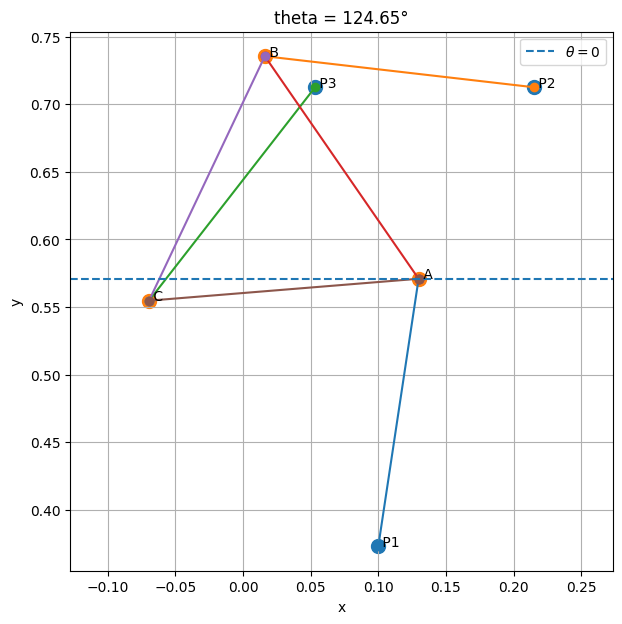

In [11]:
for i, sols in enumerate(sol):

    A = np.array(sols["A"])
    B = np.array(sols["B"])
    C = np.array(sols["C"])

    print(f"\nSolution {i+1}")
    print(f"A = ({A[0]:.4f}, {A[1]:.4f})")
    print(f"B = ({B[0]:.4f}, {B[1]:.4f})")
    print(f"C = ({C[0]:.4f}, {C[1]:.4f})")
    print(f"theta = {np.degrees(sols['theta']):.2f}°")

    plot_solution(
        sols,
        x1, y1,
        x2, y2,
        x3, y3
    )

# 4 — Chaîne complète de la Forward Kinematics

Cette dernière partie relie directement les deux premières :

1. les 6 angles donnent les trois effecteurs `F`, `E34`, `E56` des mécanismes 5-barres ;
2. ces trois points deviennent les entrées `(x1,y1)`, `(x2,y2)`, `(x3,y3)` de `solve_triangle_fk` ;
3. les différentes solutions sont affichées et dessinées.

**Paramètres à modifier :** les valeurs `l_triangle` et `d_triangle` (pour changer les dimensions des 5 bars voir plus haut)

In [ ]:
# ============================================================
# Paramètres d'entrée de la forward kinematics complète
# ============================================================

# Angles des 6 actionneurs (radians)
theta = [np.pi/2, np.pi/2,
         np.pi/2, np.pi/2,
         np.pi/2, np.pi/2]

# Géométrie reliant les 3 effecteurs 5-barres au triangle final
l_triangle = 0.2   # longueur des 3 barres F-A, E34-B, E56-C
d_triangle = 0.2   # côté du triangle équilatéral ABC 

In [16]:
# ============================================================
# 1) Calcul des 3 effecteurs des mécanismes 5-barres
# ============================================================

(F, E34, E56), (C1, D1, C2, D2, C3, D3) = compute_effectors(*theta)

print("Effecteurs des 3 mécanismes 5-barres :")
print(f"F   = ({F[0]:.6f}, {F[1]:.6f})")
print(f"E34 = ({E34[0]:.6f}, {E34[1]:.6f})")
print(f"E56 = ({E56[0]:.6f}, {E56[1]:.6f})")

# ============================================================
# 2) Ces 3 effecteurs deviennent les entrées du triangle
# ============================================================

triangle_solutions = solve_triangle_fk(
    F[0], F[1],
    E34[0], E34[1],
    E56[0], E56[1],
    l_triangle, d_triangle
)

print(f"\nNombre de solutions du mécanisme complet : {len(triangle_solutions)}")

for i, sol_triangle in enumerate(triangle_solutions):
    A = np.array(sol_triangle["A"])
    B = np.array(sol_triangle["B"])
    C = np.array(sol_triangle["C"])

    print(f"\nSolution {i+1}")
    print(f"A = ({A[0]:.6f}, {A[1]:.6f})")
    print(f"B = ({B[0]:.6f}, {B[1]:.6f})")
    print(f"C = ({C[0]:.6f}, {C[1]:.6f})")
    print(f"theta = {np.degrees(sol_triangle['theta']):.2f}°")

Effecteurs des 3 mécanismes 5-barres :
F   = (0.100000, 0.373205)
E34 = (0.214787, 0.712596)
E56 = (0.053307, 0.712596)

Nombre de solutions du mécanisme complet : 4

Solution 1
A = (-0.085193, 0.448726)
B = (0.058323, 0.588021)
C = (-0.134068, 0.642663)
theta = 44.14°

Solution 2
A = (0.298595, 0.396873)
B = (0.368256, 0.584349)
C = (0.171067, 0.550940)
theta = 69.62°

Solution 3
A = (0.055331, 0.568153)
B = (0.021866, 0.765333)
C = (-0.132165, 0.637761)
theta = 99.63°

Solution 4
A = (0.129808, 0.570971)
B = (0.016104, 0.735505)
C = (-0.069534, 0.554767)
theta = 124.65°


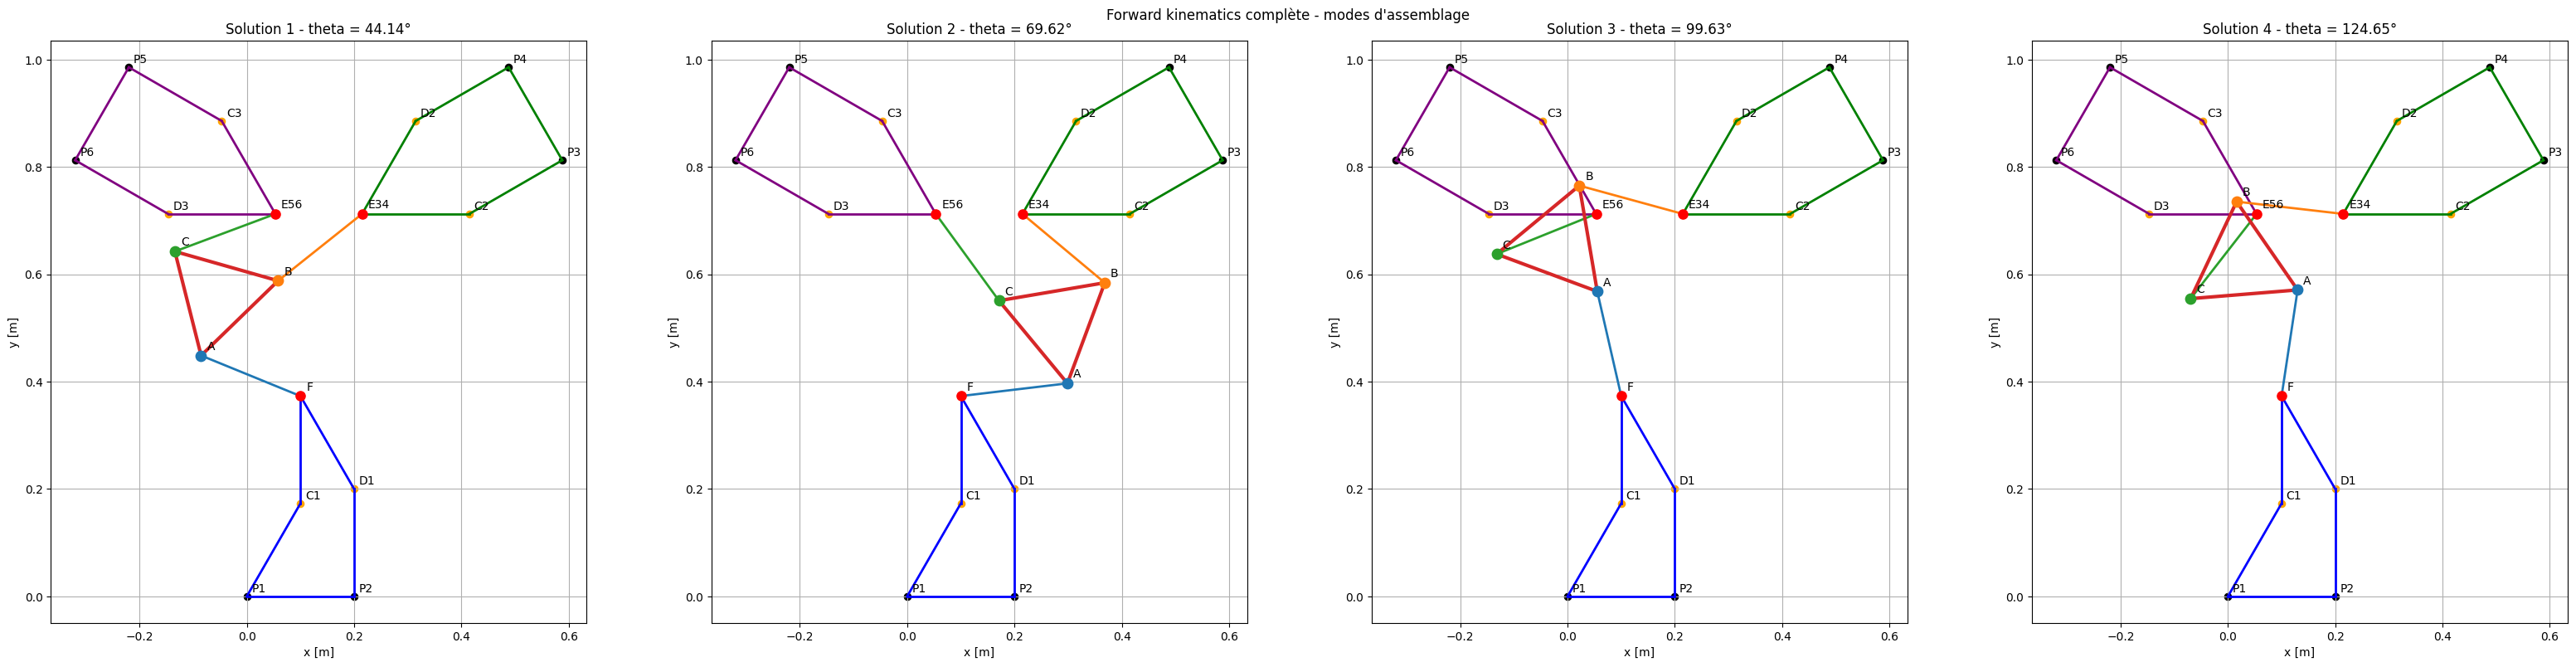

In [17]:
def draw_complete_solution(ax, sol_triangle,
                           F, E34, E56,
                           C1, D1, C2, D2, C3, D3,
                           solution_number):

    A = np.array(sol_triangle["A"])
    B = np.array(sol_triangle["B"])
    C = np.array(sol_triangle["C"])

    # --------------------------------------------------------
    # 3 mécanismes 5-barres
    # --------------------------------------------------------
    mechanisms = [
        [(P1, C1), (C1, F), (F, D1), (D1, P2), (P1, P2)],
        [(P3, C2), (C2, E34), (E34, D2), (D2, P4), (P3, P4)],
        [(P5, C3), (C3, E56), (E56, D3), (D3, P6), (P5, P6)]
    ]

    colors = ["blue", "green", "purple"]

    for bars, color in zip(mechanisms, colors):
        for P, Q in bars:
            ax.plot([P[0], Q[0]], [P[1], Q[1]],
                    color=color, linewidth=2)

    # --------------------------------------------------------
    # 3 barres reliant les effecteurs au triangle
    # --------------------------------------------------------
    ax.plot([F[0], A[0]], [F[1], A[1]], '-o', linewidth=2, label="F-A")
    ax.plot([E34[0], B[0]], [E34[1], B[1]], '-o', linewidth=2, label="E34-B")
    ax.plot([E56[0], C[0]], [E56[1], C[1]], '-o', linewidth=2, label="E56-C")

    # Triangle ABC
    ax.plot([A[0], B[0], C[0], A[0]],
            [A[1], B[1], C[1], A[1]],
            '-o', linewidth=3, label="Triangle ABC")

    # --------------------------------------------------------
    # Points et labels utiles
    # --------------------------------------------------------
    fixed_points = {
        "P1": P1, "P2": P2, "P3": P3,
        "P4": P4, "P5": P5, "P6": P6
    }
    elbow_points = {
        "C1": C1, "D1": D1, "C2": C2,
        "D2": D2, "C3": C3, "D3": D3
    }
    effectors = {"F": F, "E34": E34, "E56": E56}
    triangle_points = {"A": A, "B": B, "C": C}

    for name, p in fixed_points.items():
        ax.scatter(*p, color="black", s=35)
        ax.annotate(name, p, xytext=(4, 4), textcoords="offset points")

    for name, p in elbow_points.items():
        ax.scatter(*p, color="orange", s=35)
        ax.annotate(name, p, xytext=(4, 4), textcoords="offset points")

    for name, p in effectors.items():
        ax.scatter(*p, color="red", s=65, zorder=5)
        ax.annotate(name, p, xytext=(5, 5), textcoords="offset points")

    for name, p in triangle_points.items():
        ax.scatter(*p, s=80, zorder=6)
        ax.annotate(name, p, xytext=(5, 5), textcoords="offset points")

    ax.set_aspect("equal")
    ax.set_xlabel("x [m]")
    ax.set_ylabel("y [m]")
    ax.set_title(
        f"Solution {solution_number} - "
        f"theta = {np.degrees(sol_triangle['theta']):.2f}°"
    )
    ax.grid(True)


def plot_complete_solutions(solutions):
    if len(solutions) == 0:
        print("Aucune solution pour le triangle avec ces paramètres.")
        return

    fig, axes = plt.subplots(
        1, len(solutions),
        figsize=(8 * len(solutions), 8),
        squeeze=False
    )

    for i, sol_triangle in enumerate(solutions):
        draw_complete_solution(
            axes[0, i], sol_triangle,
            F, E34, E56,
            C1, D1, C2, D2, C3, D3,
            i + 1
        )

    fig.suptitle("Forward kinematics complète - modes d'assemblage")
    plt.tight_layout()
    plt.show()


plot_complete_solutions(triangle_solutions)